# Crack Binary Segmentation — Training

Notebook สำหรับเทียบ 2 โมเดล crack segmentation: U-Net/ResNet34 baseline และ ConvNeXt-Tiny + UPerNet ตัวหลัก พร้อม Optuna tuning แยกบน validation

- Dataset: `final_road_dataset_cleaned/manifest.csv` (ใช้คอลัมน์ `previous_split`; notebook map เป็น `split`)
- ปรับทุกอย่างบน **validation** เท่านั้น — **Final Test** ปิดไว้ด้วย `RUN_TEST = False`
- แผนรวม: `plan.md`

## 1. Setup

ติดตั้ง dependencies ของ notebook ด้วย `python -m pip install -r training-requirements.txt`. บน Huawei ให้ source CANN environment ก่อน, ติดตั้ง `torch` + `torch_npu` ตาม compatibility matrix และรัน notebook ใน container ที่เห็น NPU พร้อม mount โฟลเดอร์โปรเจกต์และ dataset

In [1]:
import os, json, math, random, time, sys
from pathlib import Path
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
try:
    import torch_npu  # registers the Ascend backend; installed only in the Huawei training environment
except ImportError:
    torch_npu = None
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
import optuna
from skimage.morphology import skeletonize
from tqdm.auto import tqdm

cv2.setNumThreads(0)  # avoid oversubscription inside DataLoader workers


def get_device(requested="auto"):
    if requested == "npu":
        if torch_npu is None or not torch.npu.is_available(): raise RuntimeError("TRAIN_DEVICE=npu แต่ torch_npu มองไม่เห็น NPU; ตรวจ CANN/driver และ ASCEND_RT_VISIBLE_DEVICES")
        return torch.device("npu:0")
    if requested == "cuda":
        if not torch.cuda.is_available(): raise RuntimeError("TRAIN_DEVICE=cuda แต่ CUDA ใช้ไม่ได้")
        return torch.device("cuda")
    if requested == "mps":
        if not torch.backends.mps.is_available(): raise RuntimeError("TRAIN_DEVICE=mps แต่ MPS ใช้ไม่ได้")
        return torch.device("mps")
    if requested != "auto": raise ValueError(f"Unknown TRAIN_DEVICE={requested!r}")
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch_npu is not None and torch.npu.is_available():
        return torch.device("npu:0")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if torch_npu is not None and torch.npu.is_available():
        torch.npu.manual_seed_all(seed)


REQUESTED_DEVICE = os.environ.get("TRAIN_DEVICE", "auto").lower()
DEVICE = get_device(REQUESTED_DEVICE)
print("device:", DEVICE, "| torch", torch.__version__, "| smp", smp.__version__, "| optuna", optuna.__version__, "| albumentations", A.__version__)
if DEVICE.type == "npu": print("Ascend device:", torch.npu.get_device_name(0), "visible count:", torch.npu.device_count())

device: mps | torch 2.10.0 | smp 0.5.0 | optuna 4.8.0 | albumentations 2.0.8


## 2. Config
ค่าทั้งหมดอยู่ที่นี่ที่เดียว — ถูกบันทึกเป็น `config.json` ในโฟลเดอร์ run

In [2]:
ROOT = Path.cwd().resolve()  # run Jupyter from the project root (also works when mounted inside a Linux container)

CFG = dict(
    # data
    dataset_dir=str(ROOT / "final_road_dataset_cleaned"),
    manifest="manifest.csv",
    split_column="previous_split",
    runs_dir=str(ROOT / "runs"),
    img_size=448,
    subset=None,            # e.g. 0.05 = use 5% of every split for a quick debug run
    # model
    model_name="unet",  # final value is set by the two-model training loop
    encoder="resnet34",
    encoder_weights="imagenet",
    model_candidates=["unet", "convnext_upernet"],
    # training
    epochs=40,
    batch_size=8,
    # macOS: forked DataLoader workers deadlock once torch/MPS threads exist, and spawn cannot
    # pickle classes defined in a notebook -> load in the main process (costs only ~5% on M2).
    num_workers=0 if DEVICE.type in {"mps", "npu"} else 4,  # conservative: NPU support smoke-test first
    lr_encoder=1e-4,
    lr_decoder=1e-3,
    weight_decay=1e-4,
    warmup_epochs=1,
    grad_clip=1.0,
    amp=DEVICE.type in {"cuda", "npu"},   # fp16 autocast; disable if a backend/operator is unstable
    # loss
    bce_weight=0.5,
    dice_weight=0.5,
    pos_weight=None,        # e.g. 3.0 if recall stays low
    # evaluation
    threshold=0.5,          # used during training; tuned on validation in section 14
    tol_px=2,               # tolerance for tol-F1
    monitor="tol_f1",       # checkpoint selection metric (validation)
    early_stop_patience=10,
    resume_from=None,       # path to a run's last.pt to continue training
    seed=42,
    optuna_trials=10,
    optuna_epochs=6,
)

RUN_OVERFIT_TEST = True   # section 10: overfit one batch to catch pipeline bugs
RUN_TEST = False          # section 15: flip to True ONCE, after model/threshold/TTA are frozen

RUN_NAME = f"{datetime.now():%Y%m%d_%H%M%S}_{CFG['model_name']}_{CFG['encoder']}"
RUN_DIR = Path(CFG["runs_dir"]) / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR / "config.json").write_text(json.dumps(CFG, indent=2))
seed_everything(CFG["seed"])
print("run dir:", RUN_DIR)

run dir: /Users/attachatchannakorn/Documents/crack-binary-segmentation/runs/20261013_131801_unet_resnet34


## 3. Manifest & splits

In [3]:
DATA_DIR = Path(CFG["dataset_dir"])
df = pd.read_csv(DATA_DIR / CFG["manifest"])

# This manifest stores the authoritative split in `previous_split`; normalize its name for the rest of this notebook.
if CFG["split_column"] not in df.columns:
    raise KeyError(f"Missing split column {CFG['split_column']!r}; found {list(df.columns)}")
df["split"] = df[CFG["split_column"]].astype(str).str.strip().str.lower()
SPLITS = ["train", "validation", "test"]
unexpected = set(df["split"].unique()) - set(SPLITS)
if unexpected:
    raise ValueError(f"Unexpected split labels: {sorted(unexpected)}")
frames = {s: df[df.split == s].reset_index(drop=True) for s in SPLITS}
if CFG["subset"]:
    frames = {s: f.sample(frac=CFG["subset"], random_state=CFG["seed"]).reset_index(drop=True)
              for s, f in frames.items()}

print({s: len(f) for s, f in frames.items()})
_all = pd.concat(frames.values(), ignore_index=True)
pd.crosstab(_all.crack_area_class, _all.split, margins=True)

{'train': 5085, 'validation': 584, 'test': 589}


split,test,train,validation,All
crack_area_class,,,,
large,160,1210,151,1521
medium,119,1324,123,1566
negative,132,1015,134,1281
small,70,705,75,850
xlarge,108,831,101,1040
All,589,5085,584,6258


## 4. Dataset class

In [4]:
class CrackDataset(Dataset):
    def __init__(self, frame, root, transform):
        self.images = [str(root / p) for p in frame.image_path]
        self.masks = [str(root / p) for p in frame.mask_path]
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = cv2.imread(self.images[i], cv2.IMREAD_COLOR)  # also drops alpha of the 4 RGBA PNGs
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        mask = (cv2.imread(self.masks[i], cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
        out = self.transform(image=img, mask=mask)
        return out["image"], out["mask"].unsqueeze(0).float(), i

## 5. Augmentation
- train: geometric + photometric + **จำลองภาพโดรน** (blur, downscale, JPEG, noise, shadow)
- val/test: normalize อย่างเดียว
- mask ใช้ nearest interpolation (ค่าเริ่มต้นของ albumentations) → ยังเป็น 0/1

In [5]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)  # ImageNet
S = CFG["img_size"]

train_tf = A.Compose([
    A.RandomResizedCrop(size=(S, S), scale=(0.5, 1.0), ratio=(0.75, 1.33), p=0.5),
    A.HorizontalFlip(),
    A.VerticalFlip(),
    A.RandomRotate90(),
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-15, 15),
             border_mode=cv2.BORDER_REFLECT_101, p=0.3),
    # photometric
    A.RandomBrightnessContrast(p=0.5),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=15, val_shift_limit=10, p=0.3),
    A.CLAHE(p=0.1),
    # drone-like degradations
    A.OneOf([A.MotionBlur(blur_limit=(3, 7)), A.GaussianBlur(blur_limit=(3, 5))], p=0.2),
    A.Downscale(scale_range=(0.5, 0.9), p=0.1),
    A.ImageCompression(quality_range=(50, 95), p=0.2),
    A.GaussNoise(std_range=(0.02, 0.06), p=0.15),
    A.RandomShadow(p=0.1),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

eval_tf = A.Compose([A.Normalize(mean=MEAN, std=STD), ToTensorV2()])

## 6. DataLoader
บน Mac ใช้ `num_workers=0` (worker แบบ fork ค้างบน macOS) — วัดแล้วโหลดข้อมูลใช้เวลาแค่ ~5% ของ train step บน M2

In [6]:
datasets = {
    "train": CrackDataset(frames["train"], DATA_DIR, train_tf),
    "validation": CrackDataset(frames["validation"], DATA_DIR, eval_tf),
    "test": CrackDataset(frames["test"], DATA_DIR, eval_tf),
}


def worker_init_fn(_):
    # every forked worker starts with the parent's RNG state -> reseed so augmentations differ
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)
    torch.utils.data.get_worker_info().dataset.transform.set_random_seed(seed)


def make_loader(split, shuffle):
    nw = CFG["num_workers"]
    return DataLoader(
        datasets[split],
        batch_size=CFG["batch_size"],
        shuffle=shuffle,
        drop_last=shuffle,
        num_workers=nw,
        pin_memory=DEVICE.type == "cuda",  # conservative default on NPU; revisit after smoke test
        persistent_workers=nw > 0,
        worker_init_fn=worker_init_fn if nw > 0 else None,
    )


loaders = {
    "train": make_loader("train", shuffle=True),
    "validation": make_loader("validation", shuffle=False),
    "test": make_loader("test", shuffle=False),
}
print({s: len(l) for s, l in loaders.items()}, "batches")

{'train': 635, 'validation': 73, 'test': 74} batches


## 7. Sanity check — data

image (8, 3, 448, 448) torch.float32 range [-2.12, 2.64]
mask  (8, 1, 448, 448) torch.float32 values [0.0, 1.0] crack ratio 0.0426
loader throughput: 67.3 img/s


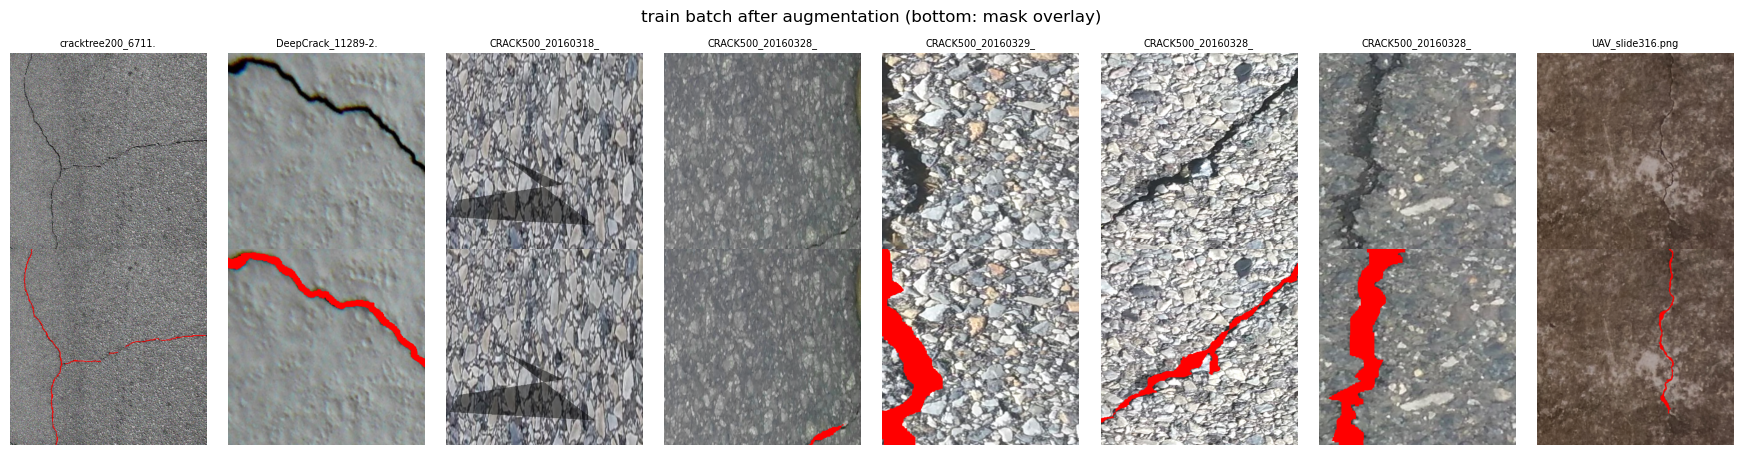

In [7]:
xb, yb, ib = next(iter(loaders["train"]))
print("image", tuple(xb.shape), xb.dtype, f"range [{xb.min():.2f}, {xb.max():.2f}]")
print("mask ", tuple(yb.shape), yb.dtype, "values", yb.unique().tolist(), f"crack ratio {yb.mean():.4f}")
assert xb.shape[1:] == (3, S, S) and yb.shape[1:] == (1, S, S)
assert set(yb.unique().tolist()) <= {0.0, 1.0}

xv, yv, _ = next(iter(loaders["validation"]))
assert set(yv.unique().tolist()) <= {0.0, 1.0}

t0 = time.time()
for k, _ in zip(range(20), loaders["train"]):
    pass
print(f"loader throughput: {20 * CFG['batch_size'] / (time.time() - t0):.1f} img/s")


def denorm(x):
    x = x.permute(1, 2, 0).cpu().numpy() * STD + MEAN
    return np.clip(x, 0, 1)


def overlay(img, mask, color=(1, 0, 0)):
    out = img.copy()
    out[mask > 0.5] = color
    return out


n = min(8, len(xb))
fig, axes = plt.subplots(2, n, figsize=(2.2 * n, 4.6))
for j in range(n):
    name = frames["train"].sample_id[int(ib[j])]
    axes[0, j].imshow(denorm(xb[j])); axes[0, j].set_title(name[:18], fontsize=7)
    axes[1, j].imshow(overlay(denorm(xb[j]), yb[j, 0].numpy()))
for a in axes.ravel():
    a.axis("off")
plt.suptitle("train batch after augmentation (bottom: mask overlay)")
plt.tight_layout(); plt.show()

## 8. Model

In [8]:
class ConvNeXtUPerNet(nn.Module):
    """ConvNeXt-Tiny + UPerNet-style decoder; module names match drone_inference/pipeline.py."""
    def __init__(self, pretrained=True):
        super().__init__()
        def norm(channels): return nn.GroupNorm(32, channels)
        weights = ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None
        self.encoder = convnext_tiny(weights=weights).features
        self.psp = nn.ModuleList([
            nn.Sequential(nn.AdaptiveAvgPool2d(scale), nn.Sequential(nn.Conv2d(768, 256, 1, bias=False), norm(256), nn.ReLU(inplace=True)))
            for scale in (1, 2, 3, 6)
        ])
        self.psp_bottleneck = nn.Sequential(nn.Conv2d(1792, 256, 3, padding=1, bias=False), norm(256), nn.ReLU(inplace=True))
        self.laterals = nn.ModuleList([nn.Sequential(nn.Conv2d(ch, 256, 1, bias=False), norm(256)) for ch in (96, 192, 384)])
        self.fpn = nn.ModuleList([nn.Sequential(nn.Conv2d(256, 256, 3, padding=1, bias=False), norm(256)) for _ in range(3)])
        self.fuse = nn.Sequential(nn.Sequential(nn.Conv2d(1024, 256, 3, padding=1, bias=False), norm(256), nn.ReLU(inplace=True)), nn.Dropout2d(.1), nn.Conv2d(256, 1, 1))
        self.aux = nn.Sequential(nn.Sequential(nn.Conv2d(384, 128, 3, padding=1, bias=False), norm(128), nn.ReLU(inplace=True)), nn.Dropout2d(.1), nn.Conv2d(128, 1, 1))

    def forward(self, x):
        input_size = x.shape[-2:]
        features = []
        for i, layer in enumerate(self.encoder):
            x = layer(x)
            if i in (1, 3, 5, 7): features.append(x)
        c1, c2, c3, c4 = features
        pooled = [c4]
        for branch in self.psp:
            pooled_input = c4
            if c4.device.type == "mps": pooled_input = F.adaptive_avg_pool2d(c4.cpu(), branch[0].output_size).to(c4.device)
            pooled.append(F.interpolate(branch[1](pooled_input), size=c4.shape[-2:], mode="bilinear", align_corners=False))
        top = self.psp_bottleneck(torch.cat(pooled, dim=1))
        laterals = [layer(feature) for layer, feature in zip(self.laterals, (c1, c2, c3))] + [top]
        for i in range(2, -1, -1): laterals[i] = laterals[i] + F.interpolate(laterals[i + 1], size=laterals[i].shape[-2:], mode="bilinear", align_corners=False)
        pyramid = [layer(feature) for layer, feature in zip(self.fpn, laterals[:3])] + [laterals[3]]
        target = pyramid[0].shape[-2:]
        pyramid = [pyramid[0]] + [F.interpolate(feature, size=target, mode="bilinear", align_corners=False) for feature in pyramid[1:]]
        return F.interpolate(self.fuse(torch.cat(pyramid, dim=1)), size=input_size, mode="bilinear", align_corners=False)


def build_model(model_name=None):
    name = model_name or CFG["model_name"]
    if name == "unet":
        m = smp.Unet(CFG["encoder"], encoder_weights=CFG["encoder_weights"], classes=1)
    elif name == "convnext_upernet":
        m = ConvNeXtUPerNet(pretrained=(CFG["encoder_weights"] == "imagenet"))
    else:
        raise ValueError(f"Unknown model_name={name!r}")
    return m.to(DEVICE)


for _name in CFG["model_candidates"]:
    _model = build_model(_name)
    _n_params = sum(p.numel() for p in _model.parameters())
    _model.eval()
    with torch.no_grad():
        _out = _model(xb[:2].to(DEVICE))
    print(f"{_name}: {_n_params / 1e6:.2f}M params, output {tuple(_out.shape)}")
    assert _out.shape == (2, 1, S, S)
    del _model, _out
    if DEVICE.type == "mps": torch.mps.empty_cache()
    elif DEVICE.type == "cuda": torch.cuda.empty_cache()
    elif DEVICE.type == "npu": torch.npu.empty_cache()

unet: 24.44M params, output (2, 1, 448, 448)
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /Users/attachatchannakorn/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:28<00:00, 3.98MB/s] 


convnext_upernet: 37.48M params, output (2, 1, 448, 448)


## 9. Loss & Metrics
- **Loss** = BCE + (1 − Dice) โดย Dice คิดระดับ **batch** (รวมทั้ง batch) กัน 0/0 จากรูปที่ mask ว่าง
- **Metrics** สะสม TP/FP/FN ทั้ง dataset (micro): IoU, Dice (= pixel F1), Precision, Recall
- **tol-F1**: ยอมคลาดได้ `tol_px` พิกเซล (Chebyshev) — pred ที่อยู่ใกล้ GT นับถูก, GT ที่มี pred อยู่ใกล้นับเจอ

In [9]:
class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, dice_weight=0.5, pos_weight=None, eps=1.0):
        super().__init__()
        pw = torch.tensor([pos_weight]) if pos_weight else None
        self.bce = nn.BCEWithLogitsLoss(pos_weight=pw)
        self.bw, self.dw, self.eps = bce_weight, dice_weight, eps

    def forward(self, logits, target):
        bce = self.bce(logits, target)
        p = torch.sigmoid(logits)
        dice = (2 * (p * target).sum() + self.eps) / (p.sum() + target.sum() + self.eps)
        return self.bw * bce + self.dw * (1 - dice)


criterion = BCEDiceLoss(CFG["bce_weight"], CFG["dice_weight"], CFG["pos_weight"]).to(DEVICE)

COUNT_KEYS = ["tp", "fp", "fn", "pred_near_gt", "gt_near_pred"]


def dilate(m, r):
    return F.max_pool2d(m, 2 * r + 1, stride=1, padding=r) if r > 0 else m


@torch.no_grad()
def batch_counts(prob, target, thr, tol):
    """Per-image pixel counts, shape (N, 5) in COUNT_KEYS order."""
    pred = (prob > thr).float()
    dims = (1, 2, 3)
    tp = (pred * target).sum(dims)
    fp = (pred * (1 - target)).sum(dims)
    fn = ((1 - pred) * target).sum(dims)
    pred_near_gt = (pred * dilate(target, tol)).sum(dims)
    gt_near_pred = (target * dilate(pred, tol)).sum(dims)
    return torch.stack([tp, fp, fn, pred_near_gt, gt_near_pred], 1)


def summarize(c):
    tp, fp, fn, png, gnp = [float(v) for v in c]
    eps = 1e-9
    p, r = tp / (tp + fp + eps), tp / (tp + fn + eps)
    tp_, tr_ = png / (tp + fp + eps), gnp / (tp + fn + eps)
    return dict(
        iou=tp / (tp + fp + fn + eps),
        dice=2 * tp / (2 * tp + fp + fn + eps),
        precision=p,
        recall=r,
        tol_precision=tp_,
        tol_recall=tr_,
        tol_f1=2 * tp_ * tr_ / (tp_ + tr_ + eps),
    )


# quick self-check: perfect prediction -> all metrics 1
_c = batch_counts(yb.to(DEVICE), yb.to(DEVICE), 0.5, CFG["tol_px"]).sum(0).cpu()
print({k: round(v, 4) for k, v in summarize(_c).items()})

{'iou': 1.0, 'dice': 1.0, 'precision': 1.0, 'recall': 1.0, 'tol_precision': 1.0, 'tol_recall': 1.0, 'tol_f1': 1.0}


## 10. Sanity check — overfit 1 batch
ถ้า pipeline ถูก loss ต้องลดลงชัดเจนภายในไม่กี่สิบ step (ใช้โมเดลแยก ไม่กระทบโมเดลจริง)

In [10]:
if RUN_OVERFIT_TEST:
    m = build_model()
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
    x_, y_ = xb.to(DEVICE), yb.to(DEVICE)
    m.train()
    losses = []
    for step in range(60):
        opt.zero_grad(set_to_none=True)
        loss = criterion(m(x_), y_)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    print("loss:", " ".join(f"{l:.3f}" for l in losses[::10]), f"-> {losses[-1]:.3f}")
    m.eval()
    with torch.no_grad():
        print("train-batch metrics:", {k: round(v, 3) for k, v in summarize(
            batch_counts(torch.sigmoid(m(x_)), y_, 0.5, CFG["tol_px"]).sum(0).cpu()).items()})
    assert losses[-1] < 0.5 * losses[0], "loss did not drop — check data/model/loss"
    del m, opt

loss: 0.775 0.435 0.306 0.222 0.156 0.112 -> 0.080
train-batch metrics: {'iou': 0.926, 'dice': 0.961, 'precision': 0.952, 'recall': 0.971, 'tol_precision': 0.999, 'tol_recall': 0.995, 'tol_f1': 0.997}


## 11. Optimizer & Scheduler
AdamW แยก lr encoder (pretrained, ต่ำ) กับ decoder (สูง) + linear warmup → cosine (step ทุก batch)

In [11]:
def make_optimizer_scheduler(epochs):
    enc_params = list(model.encoder.parameters())
    enc_ids = {id(p) for p in enc_params}
    dec_params = [p for p in model.parameters() if id(p) not in enc_ids]
    opt = torch.optim.AdamW(
        [{"params": enc_params, "lr": CFG["lr_encoder"]},
         {"params": dec_params, "lr": CFG["lr_decoder"]}],
        weight_decay=CFG["weight_decay"],
    )
    steps = len(loaders["train"])
    total, warmup = max(1, epochs * steps), max(1, CFG["warmup_epochs"] * steps)
    def lr_lambda(step):
        if step < warmup: return (step + 1) / warmup
        progress = (step - warmup) / max(1, total - warmup)
        return 0.5 * (1 + math.cos(math.pi * min(1.0, progress)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    if DEVICE.type == "cuda":
        grad_scaler = torch.amp.GradScaler("cuda", enabled=CFG["amp"])
    elif DEVICE.type == "npu":
        grad_scaler = torch.npu.amp.GradScaler(enabled=CFG["amp"])
    else:
        grad_scaler = torch.amp.GradScaler("cuda", enabled=False)
    return opt, sched, grad_scaler


model = build_model()
optimizer, scheduler, scaler = make_optimizer_scheduler(CFG["epochs"])
start_epoch, history, best_score = 1, [], -1.0
if CFG["resume_from"]:
    ck = torch.load(CFG["resume_from"], map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
    start_epoch, history, best_score = ck["epoch"] + 1, ck["history"], ck["best_score"]
    print(f"resumed from {CFG['resume_from']} at epoch {start_epoch}")
print(f"{len(loaders['train'])} steps/epoch")

635 steps/epoch


## 12. Optuna tuning + train โมเดลทั้งสองตัว
ทำ study แยกสำหรับ U-Net และ ConvNeXt-UPerNet จากนั้น train เต็มทั้งสองโมเดลด้วย best params ของตัวเอง; เก็บ `best.pt`/`last.pt` และเทียบ validation metrics ใน `model_comparison_validation.csv`. Test set ยังไม่ถูกใช้

In [12]:
def autocast():
    return torch.autocast(DEVICE.type, dtype=torch.float16, enabled=CFG["amp"])


def train_one_epoch(epoch):
    model.train()
    total, n = 0.0, 0
    pbar = tqdm(loaders["train"], desc=f"epoch {epoch} train", leave=False)
    for x, y, _ in pbar:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast():
            logits = model(x)
        loss = criterion(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total += loss.item() * len(x)
        n += len(x)
        pbar.set_postfix(loss=f"{total / n:.4f}")
    return total / n


@torch.no_grad()
def evaluate(loader, thr):
    model.eval()
    total, n, counts = 0.0, 0, []
    for x, y, _ in tqdm(loader, desc="eval", leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        with autocast():
            logits = model(x)
        logits = logits.float()
        total += criterion(logits, y).item() * len(x)
        n += len(x)
        counts.append(batch_counts(torch.sigmoid(logits), y, thr, CFG["tol_px"]).cpu())
    return {"loss": total / n, **summarize(torch.cat(counts).sum(0))}


FINAL_EPOCHS = CFG["epochs"]
HPO_EPOCHS = CFG["optuna_epochs"]
N_TRIALS = CFG["optuna_trials"]
BEST_HPARAMS = {}

def optuna_objective(trial, model_name):
    global model, criterion, optimizer, scheduler, scaler
    CFG["model_name"] = model_name
    CFG["epochs"] = HPO_EPOCHS
    CFG["lr_encoder"] = trial.suggest_float("lr_encoder", 2e-5, 4e-4, log=True)
    CFG["lr_decoder"] = trial.suggest_float("lr_decoder", 2e-4, 3e-3, log=True)
    CFG["weight_decay"] = trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True)
    CFG["bce_weight"] = trial.suggest_float("bce_weight", 0.25, 0.75)
    CFG["dice_weight"] = 1.0 - CFG["bce_weight"]
    CFG["pos_weight"] = trial.suggest_float("pos_weight", 1.0, 4.0)
    seed_everything(CFG["seed"])
    model = build_model(model_name)
    criterion = BCEDiceLoss(CFG["bce_weight"], CFG["dice_weight"], CFG["pos_weight"]).to(DEVICE)
    optimizer, scheduler, scaler = make_optimizer_scheduler(HPO_EPOCHS)
    best = -1.0
    for epoch in range(1, HPO_EPOCHS + 1):
        train_one_epoch(epoch)
        val = evaluate(loaders["validation"], CFG["threshold"])
        score = float(val[CFG["monitor"]])
        best = max(best, score)
        trial.report(score, step=epoch)
        if trial.should_prune(): raise optuna.TrialPruned()
    del model, optimizer, scheduler, scaler, criterion
    if DEVICE.type == "mps": torch.mps.empty_cache()
    elif DEVICE.type == "cuda": torch.cuda.empty_cache()
    elif DEVICE.type == "npu": torch.npu.empty_cache()
    return best

# Each architecture gets an independent TPE study; only train/validation are used here.
for model_name in CFG["model_candidates"]:
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=CFG["seed"]),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=2),
                                study_name=f"{model_name}_{datetime.now():%Y%m%d_%H%M%S}")
    study.optimize(lambda trial: optuna_objective(trial, model_name), n_trials=N_TRIALS, gc_after_trial=True)
    BEST_HPARAMS[model_name] = study.best_params
    study.trials_dataframe().to_csv(RUN_DIR / f"optuna_{model_name}.csv", index=False)
    print(model_name, "best validation tol-F1:", round(study.best_value, 4), study.best_params)
(RUN_DIR / "optuna_best_params.json").write_text(json.dumps(BEST_HPARAMS, indent=2))

# Full runs for both candidates, initialized from their own Optuna best settings.
TRAINING_SUMMARY = []
for model_name in CFG["model_candidates"]:
    CFG["model_name"] = model_name
    CFG["epochs"] = FINAL_EPOCHS
    CFG.update({k: v for k, v in BEST_HPARAMS[model_name].items() if k in {"lr_encoder", "lr_decoder", "weight_decay", "bce_weight", "pos_weight"}})
    CFG["dice_weight"] = 1.0 - CFG["bce_weight"]
    seed_everything(CFG["seed"])
    model = build_model(model_name)
    criterion = BCEDiceLoss(CFG["bce_weight"], CFG["dice_weight"], CFG["pos_weight"]).to(DEVICE)
    optimizer, scheduler, scaler = make_optimizer_scheduler(FINAL_EPOCHS)
    RUN_NAME = f"{datetime.now():%Y%m%d_%H%M%S}_{model_name}"
    RUN_DIR = Path(CFG["runs_dir"]) / RUN_NAME
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    (RUN_DIR / "config.json").write_text(json.dumps({**CFG, "optuna_best_params": BEST_HPARAMS[model_name]}, indent=2))
    history, best_score, bad_epochs = [], -1.0, 0
    for epoch in range(1, FINAL_EPOCHS + 1):
        t0 = time.time()
        train_loss = train_one_epoch(epoch)
        val = evaluate(loaders["validation"], CFG["threshold"])
        row = {"epoch": epoch, "train_loss": train_loss, **{f"val_{k}": v for k, v in val.items()},
               "lr_decoder": optimizer.param_groups[1]["lr"], "time_s": time.time() - t0}
        history.append(row); pd.DataFrame(history).to_csv(RUN_DIR / "history.csv", index=False)
        score = val[CFG["monitor"]]; improved = score > best_score
        if improved: best_score, bad_epochs = score, 0
        else: bad_epochs += 1
        print(f"{model_name} [{epoch:3d}] loss {train_loss:.4f} | val IoU {val['iou']:.4f} Dice {val['dice']:.4f} tol-F1 {val['tol_f1']:.4f}")
        ckpt = {"model": model.state_dict(), "epoch": epoch, "cfg": dict(CFG), "config": {"model": model_name}, "val": val, "history": history, "best_score": best_score}
        if improved: torch.save(ckpt, RUN_DIR / "best.pt")
        ckpt.update(optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(), scaler=scaler.state_dict())
        torch.save(ckpt, RUN_DIR / "last.pt")
        if bad_epochs >= CFG["early_stop_patience"]: print("early stop"); break
    best_ckpt = torch.load(RUN_DIR / "best.pt", map_location="cpu", weights_only=False)
    TRAINING_SUMMARY.append({"model": model_name, "run_dir": str(RUN_DIR), "best_epoch": best_ckpt["epoch"], "val_iou": best_ckpt["val"]["iou"], "val_dice": best_ckpt["val"]["dice"], "val_tol_f1": best_ckpt["val"]["tol_f1"]})
    del model, optimizer, scheduler, scaler, criterion
    if DEVICE.type == "mps": torch.mps.empty_cache()
    elif DEVICE.type == "cuda": torch.cuda.empty_cache()
    elif DEVICE.type == "npu": torch.npu.empty_cache()

pd.DataFrame(TRAINING_SUMMARY).to_csv(Path(CFG["runs_dir"]) / "model_comparison_validation.csv", index=False)
display(pd.DataFrame(TRAINING_SUMMARY))
# Continue validation analysis below on the primary model (ConvNeXt-UPerNet).
CFG["model_name"] = "convnext_upernet"
CFG["epochs"] = FINAL_EPOCHS
CFG.update({k: v for k, v in BEST_HPARAMS[CFG["model_name"]].items() if k in {"lr_encoder", "lr_decoder", "weight_decay", "bce_weight", "pos_weight"}})
CFG["dice_weight"] = 1.0 - CFG["bce_weight"]
RUN_DIR = Path(TRAINING_SUMMARY[-1]["run_dir"])
model = build_model(CFG["model_name"])
model.load_state_dict(torch.load(RUN_DIR / "best.pt", map_location=DEVICE, weights_only=False)["model"])
model.eval()
criterion = BCEDiceLoss(CFG["bce_weight"], CFG["dice_weight"], CFG["pos_weight"]).to(DEVICE)
optimizer, scheduler, scaler = make_optimizer_scheduler(FINAL_EPOCHS)

[I 2026-10-13 13:21:14,538] A new study created in memory with name: unet_20261013_132114


epoch 1 train:   0%|          | 0/635 [00:00<?, ?it/s]

eval:   0%|          | 0/73 [00:00<?, ?it/s]

epoch 2 train:   0%|          | 0/635 [00:00<?, ?it/s]

eval:   0%|          | 0/73 [00:00<?, ?it/s]

...

epoch 4 train:   0%|          | 0/635 [00:00<?, ?it/s]

eval:   0%|          | 0/73 [00:00<?, ?it/s]

epoch 5 train:   0%|          | 0/635 [00:00<?, ?it/s]

[W 2026-10-13 15:00:16,765] Trial 0 failed with parameters: {'lr_encoder': 6.142114735554742e-05, 'lr_decoder': 0.0026251660632419286, 'weight_decay': 0.00015702970884055374, 'bce_weight': 0.5493292420985183, 'pos_weight': 1.4680559213273097} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/site-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "/var/folders/nd/1mgzqyyx47d8bq46k7rzvwlw0000gn/T/ipykernel_75726/1935274824.py", line 80, in <lambda>
    study.optimize(lambda trial: optuna_objective(trial, model_name), n_trials=N_TRIALS, gc_after_trial=True)
                                 ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/var/folders/nd/1mgzqyyx47d8bq46k7rzvwlw0000gn/T/ipykernel_75726/1935274824.py", line 63, in optuna_objective
    train_one_epoch(epoch)
    ~~~~~~~~~~~~~~~^^^^^^^
  File "/var/folders/nd/1mgzqyyx47d8bq46k7rzvwlw0000gn/T/ipykernel_757

KeyboardInterrupt: 

## 13. Training curves

In [ ]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val")
ax[0].set_title("loss"); ax[0].legend()
for k in ["iou", "dice", "tol_f1"]:
    ax[1].plot(h.epoch, h[f"val_{k}"], label=k)
ax[1].set_title("val metrics @ thr=%.2f" % CFG["threshold"]); ax[1].legend()
ax[2].plot(h.epoch, h.val_precision, label="precision"); ax[2].plot(h.epoch, h.val_recall, label="recall")
ax[2].set_title("val precision / recall"); ax[2].legend()
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(RUN_DIR / "curves.png", dpi=120); plt.show()

## 14. Validation analysis (ใช้ best.pt)
1. จูน threshold (0.05–0.95) ทั้งแบบไม่มี / มี TTA (flip)
2. แยกผลตาม `crack_area_class` และ `source_dataset`
3. False alarm บนรูป negative
4. clDice (ความต่อเนื่องของรอยร้าว)
5. ดูภาพที่โมเดลพลาดมากที่สุด

ผลที่เลือก (threshold, TTA) บันทึกลง `val_selection.json` เพื่อใช้กับ Final Test

In [ ]:
best = torch.load(RUN_DIR / "best.pt", map_location=DEVICE, weights_only=False)
model.load_state_dict(best["model"])
model.eval()
print(f"loaded best.pt from epoch {best['epoch']} ({CFG['monitor']}={best['val'][CFG['monitor']]:.4f} @ thr {CFG['threshold']})")

THRS = np.round(np.arange(0.05, 0.96, 0.05), 2)


@torch.no_grad()
def predict_prob(x, tta=False):
    with autocast():
        p = torch.sigmoid(model(x).float())
        if tta:
            for dims in ([-1], [-2], [-2, -1]):
                p = p + torch.sigmoid(model(torch.flip(x, dims)).float()).flip(dims)
            p = p / 4
    return p


@torch.no_grad()
def collect_counts(loader, tta=False):
    """Per-image counts for every threshold: array (N, len(THRS), 5), in dataset order."""
    out = []
    for x, y, _ in tqdm(loader, desc=f"predict tta={tta}", leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        p = predict_prob(x, tta)
        out.append(torch.stack([batch_counts(p, y, t, CFG["tol_px"]) for t in THRS], 1).cpu())
    return torch.cat(out).numpy()


def threshold_table(C):
    return pd.DataFrame([{"thr": t, **summarize(C[:, i].sum(0))} for i, t in enumerate(THRS)])


val_frame = frames["validation"]
C_plain = collect_counts(loaders["validation"], tta=False)
C_tta = collect_counts(loaders["validation"], tta=True)
tab_plain, tab_tta = threshold_table(C_plain), threshold_table(C_tta)

mon = CFG["monitor"]
bp, bt = tab_plain.loc[tab_plain[mon].idxmax()], tab_tta.loc[tab_tta[mon].idxmax()]
USE_TTA = bool(bt[mon] > bp[mon] + 0.002)   # only keep TTA if it clearly helps (it costs 4x inference)
BEST_THR = float(bt.thr if USE_TTA else bp.thr)
C_best = (C_tta if USE_TTA else C_plain)[:, list(THRS).index(BEST_THR)]

print(f"best no-TTA: thr {bp.thr:.2f} {mon} {bp[mon]:.4f} | best TTA: thr {bt.thr:.2f} {mon} {bt[mon]:.4f}")
print(f"-> selected thr={BEST_THR:.2f}, TTA={USE_TTA}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, tab in [("no TTA", tab_plain), ("TTA", tab_tta)]:
    ax[0].plot(tab.thr, tab[mon], label=f"{mon} {name}"); ax[0].plot(tab.thr, tab.dice, "--", label=f"dice {name}")
    ax[1].plot(tab.recall, tab.precision, label=name)
ax[0].axvline(BEST_THR, color="k", lw=0.8); ax[0].set_xlabel("threshold"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("PR (pixel)"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
tab_plain.round(4)

In [ ]:
# per crack-area class and per source, at the selected threshold / TTA
def grouped(frame, C, col):
    rows = []
    for g, idx in frame.groupby(col).groups.items():
        rows.append({col: g, "n": len(idx), **summarize(C[idx].sum(0))})
    return pd.DataFrame(rows).set_index(col)


metric_cols = ["n", "iou", "dice", "precision", "recall", "tol_f1"]
by_class = grouped(val_frame, C_best, "crack_area_class").loc[["small", "medium", "large", "xlarge"], metric_cols]
by_source = grouped(val_frame, C_best, "source_dataset")[metric_cols].sort_values("tol_f1")

neg = val_frame.crack_area_class.eq("negative").to_numpy()
fp_px = C_best[neg, 1]
neg_report = {
    "negative_images": int(neg.sum()),
    "any_fp_rate": float((fp_px > 0).mean()),
    "fp_ge_100px_rate": float((fp_px >= 100).mean()),
    "mean_fp_px": float(fp_px.mean()),
}
print("negatives:", neg_report)
display(by_class.round(4))
display(by_source.round(4))

In [ ]:
# clDice + worst cases need the actual binary predictions
@torch.no_grad()
def predict_masks(loader, thr, tta):
    preds = []
    for x, _, _ in tqdm(loader, desc="masks", leave=False):
        preds.append((predict_prob(x.to(DEVICE), tta) > thr).cpu().numpy()[:, 0])
    return np.concatenate(preds)


def cldice_counts(pred, gt):
    """Numerators/denominators of clDice (topology precision / sensitivity)."""
    sp, sg = skeletonize(pred), skeletonize(gt)
    return np.array([(sp & gt).sum(), sp.sum(), (sg & pred).sum(), sg.sum()], dtype=np.float64)


val_pred = predict_masks(loaders["validation"], BEST_THR, USE_TTA)
val_gt = np.stack([cv2.imread(str(DATA_DIR / p), cv2.IMREAD_GRAYSCALE) > 127 for p in val_frame.mask_path])

pos = np.nonzero(~neg)[0]
cl = np.sum([cldice_counts(val_pred[i], val_gt[i]) for i in tqdm(pos, desc="clDice", leave=False)], axis=0)
t_prec, t_sens = cl[0] / max(cl[1], 1), cl[2] / max(cl[3], 1)
cldice = float(2 * t_prec * t_sens / max(t_prec + t_sens, 1e-9))
print(f"clDice {cldice:.4f} (topology precision {t_prec:.4f}, sensitivity {t_sens:.4f})")

val_summary = {"threshold": BEST_THR, "tta": USE_TTA, "epoch": best["epoch"],
               **summarize(C_best.sum(0)), "cldice": cldice, "negatives": neg_report}
(RUN_DIR / "val_selection.json").write_text(json.dumps(val_summary, indent=2))
by_class.to_csv(RUN_DIR / "val_by_class.csv"); by_source.to_csv(RUN_DIR / "val_by_source.csv")
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in val_summary.items()}

In [ ]:
# worst positives by per-image tol-F1
def per_image_tol_f1(C):
    tp, fp, fn, png, gnp = C.T
    p, r = png / np.maximum(tp + fp, 1), gnp / np.maximum(tp + fn, 1)
    return 2 * p * r / np.maximum(p + r, 1e-9)


f1_img = per_image_tol_f1(C_best)
worst = pos[np.argsort(f1_img[pos])[:6]]
fig, axes = plt.subplots(len(worst), 3, figsize=(9, 3 * len(worst)))
for row, i in zip(axes, worst):
    r = val_frame.iloc[i]
    img = cv2.cvtColor(cv2.imread(str(DATA_DIR / r.image_path)), cv2.COLOR_BGR2RGB) / 255.0
    row[0].imshow(img); row[0].set_title(f"{r.sample_id[:28]}\n{r.source_dataset} / {r.crack_area_class}", fontsize=8)
    row[1].imshow(overlay(img, val_gt[i], (0, 1, 0))); row[1].set_title("GT", fontsize=8)
    row[2].imshow(overlay(img, val_pred[i])); row[2].set_title(f"pred (tol-F1 {f1_img[i]:.2f})", fontsize=8)
    for a in row:
        a.axis("off")
plt.tight_layout(); plt.show()

## 15. Final Test — รันครั้งเดียว
ใช้ best.pt + threshold + TTA ที่เลือกจาก validation เท่านั้น ห้ามกลับไปปรับอะไรหลังเห็นผลนี้

In [ ]:
if RUN_TEST:
    sel = json.loads((RUN_DIR / "val_selection.json").read_text())
    test_frame = frames["test"]
    idx = list(THRS).index(sel["threshold"])
    C_test = collect_counts(loaders["test"], tta=sel["tta"])[:, idx]
    test_pred = predict_masks(loaders["test"], sel["threshold"], sel["tta"])
    test_gt = np.stack([cv2.imread(str(DATA_DIR / p), cv2.IMREAD_GRAYSCALE) > 127 for p in test_frame.mask_path])
    tneg = test_frame.crack_area_class.eq("negative").to_numpy()
    cl = np.sum([cldice_counts(test_pred[i], test_gt[i]) for i in np.nonzero(~tneg)[0]], axis=0)
    tp_, ts_ = cl[0] / max(cl[1], 1), cl[2] / max(cl[3], 1)
    test_summary = {**sel, **summarize(C_test.sum(0)), "cldice": float(2 * tp_ * ts_ / max(tp_ + ts_, 1e-9)),
                    "any_fp_rate_negatives": float((C_test[tneg, 1] > 0).mean())}
    test_summary.pop("negatives", None)
    (RUN_DIR / "test_results.json").write_text(json.dumps(test_summary, indent=2))
    grouped(test_frame, C_test, "crack_area_class").to_csv(RUN_DIR / "test_by_class.csv")
    grouped(test_frame, C_test, "source_dataset").to_csv(RUN_DIR / "test_by_source.csv")
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in test_summary.items()})
else:
    print("RUN_TEST=False — skipped")